# 02 · Open-vocabulary detection on a real flower-shop video

Question: can a detector that was **never trained on flowers** find them in
a real shop video if we just type a word like "flower"? And which model is the best
trade-off on a **CPU-only laptop**?

We take a vlog filmed in a flower boutique (a presenter, buckets of flowers,
mixed bouquets, plus long street scenes with no flowers) and compare three
open-vocabulary detectors: **Grounding DINO tiny**, **MM-Grounding-DINO tiny**
and **OWLv2 base**. Everything here runs on CPU, one frame at a time, so the
timings are what *this* laptop gives you.

> **About the video.** It is under the standard YouTube licence (all rights
> reserved by its creator). It is downloaded once for private analysis into
> the git-ignored `data/raw/videos/`, with a sidecar JSON recording where it
> came from. Do not commit or redistribute it, or frames taken from it.

**Run it:** `pip install -r requirements-notebook.txt`, select the project's
`.venv` kernel. First run downloads the video (~106 MB) and three models
(~2 GB); the full notebook then takes roughly 35 minutes on CPU.

Contents: 1 Get the video · 2 What is in it · 3 Benchmark the detectors ·
4 Side by side · 5 Prompts · 6 Thresholds and box sizes · 7 Run on a clip ·
8 One second at full frame rate · 9 Take-aways

In [1]:
import gc
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from bouquet_checker import video
from bouquet_checker.detection import OpenVocabDetector, draw_detections

# Inline figures as JPEG (quality 90) to keep the saved notebook small.
%config InlineBackend.figure_format = "jpeg"
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 90}}

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False,
                     "axes.spines.right": False})
pd.set_option("display.width", 160)

VIDEO_URL = "https://www.youtube.com/watch?v=QSVyyrKea14"

MODELS = {
    "grounding-dino-tiny": "IDEA-Research/grounding-dino-tiny",
    "mm-grounding-dino-tiny":
        "openmmlab-community/mm_grounding_dino_tiny_o365v1_goldg_v3det",
    "owlv2-base": "google/owlv2-base-patch16-ensemble",
}

## 1 · Get the video

`download_video` fetches it **once** (video stream only, 720p H.264, so no
ffmpeg needed) and reuses the file afterwards. The sidecar JSON keeps the
source and licence next to the file.

In [2]:
path = video.download_video(VIDEO_URL, max_height=720)
info = video.video_info(path)
provenance = video.read_provenance(path)

print(f"file      : {path.name} ({path.stat().st_size / 1e6:.0f} MB)")
print(f"size      : {info.width}x{info.height} @ {info.fps:.0f} fps")
print(f"length    : {info.duration_s:.0f} s ({info.frame_count:,} frames)")
print(f"title     : {provenance['title']}")
print(f"uploader  : {provenance['uploader']}")
print(f"licence   : {provenance['license']}")

file      : QSVyyrKea14.mp4 (106 MB)
size      : 1280x720 @ 30 fps
length    : 399 s (11,968 frames)
title     : 🌹 Fast Guide to Choosing the Best Flowers for Your Woman 💐
uploader  : Iryna Bushmina
licence   : Standard YouTube License


## 2 · What is in it

One frame every 20 seconds. Roughly 60-260 s is the shop (buckets of cut
flowers, bouquets, shelves); the rest is the presenter on the street. That
split is useful: the street scenes are **negatives**, where a good detector
should stay quiet.

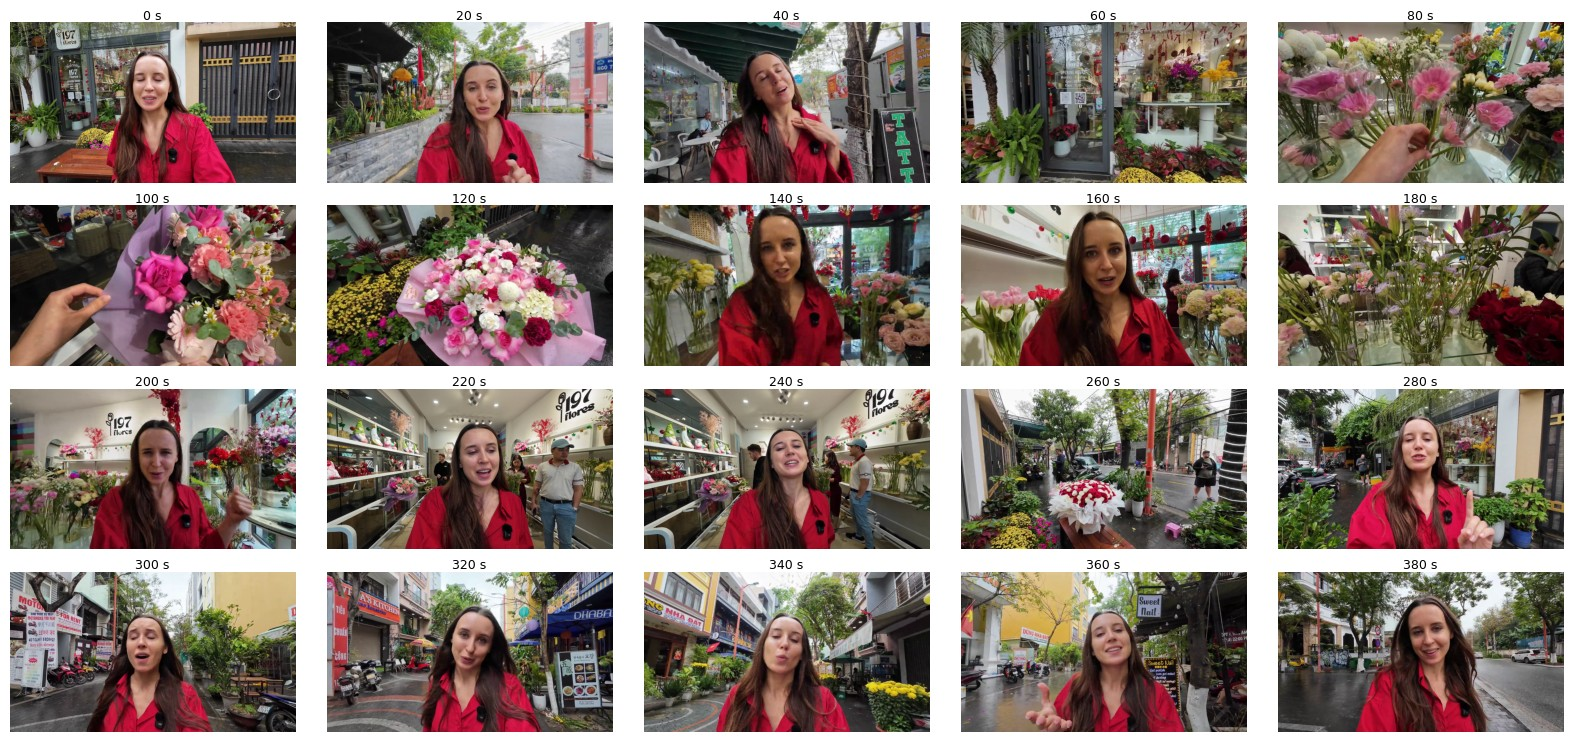

In [3]:
overview = list(video.sample_frames(path, every_s=20))
fig, axes = plt.subplots(4, 5, figsize=(16, 7.5))
for ax, frame in zip(axes.ravel(), overview):
    ax.imshow(frame.image)
    ax.set_title(f"{frame.time_s:.0f} s", fontsize=9, pad=2)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3 · Benchmark the detectors

We pick nine frames by hand: **seven with flowers** (bouquet close-ups, shop
buckets, shelves, a wide shot) and **two street scenes** where the right
answer is "nothing". Each model runs one at a time (so they do not fight for
the CPU) with two prompts: **"flower"** and **"flower head"** (a first version
of this notebook used only "flower" and, as section 5 shows, that boxes whole
bouquets; comparing models with a weak prompt would have been unfair).

We run at a low score cut-off (0.10) once and filter afterwards, which gives
the same result as re-running at each threshold (NMS is consistent with
thresholding) and lets section 6 sweep thresholds for free.

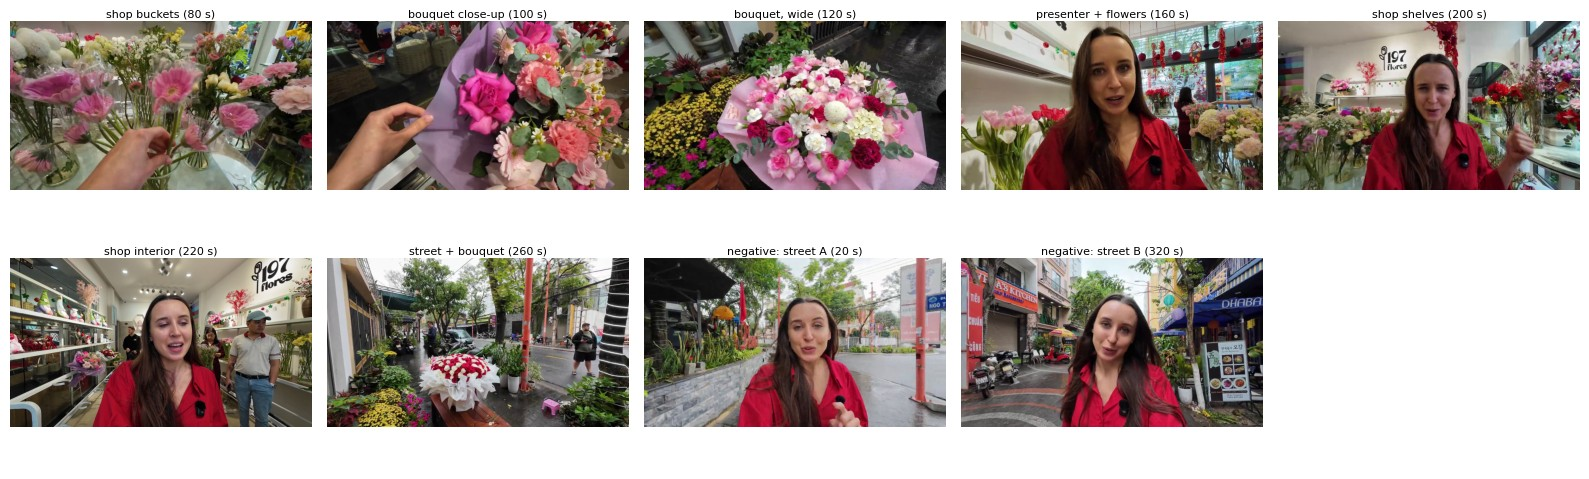

In [4]:
EVAL_TIMES = {
    "shop buckets": 80,
    "bouquet close-up": 100,
    "bouquet, wide": 120,
    "presenter + flowers": 160,
    "shop shelves": 200,
    "shop interior": 220,
    "street + bouquet": 260,
    "negative: street A": 20,
    "negative: street B": 320,
}
eval_frames = {name: video.read_frame(path, t) for name, t in EVAL_TIMES.items()}
frame_area = info.width * info.height

fig, axes = plt.subplots(2, 5, figsize=(16, 5.2))
for ax, (name, frame) in zip(axes.ravel(), eval_frames.items()):
    ax.imshow(frame.image); ax.set_title(f"{name} ({frame.time_s:.0f} s)", fontsize=8, pad=2)
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

In [5]:
BENCH_PROMPTS = {"flower": ["flower"], "flower head": ["flower head"]}
LOW = 0.10            # run once at a low cut-off, filter afterwards
records, detections = [], {}

for model_name, model_id in MODELS.items():
    t0 = time.perf_counter()
    detector = OpenVocabDetector(model_id)
    load_s = time.perf_counter() - t0
    print(f"{model_name}: loaded in {load_s:.0f} s "
          f"({sum(p.numel() for p in detector._model.parameters()) / 1e6:.0f}M parameters)")
    for prompt_name, prompts in BENCH_PROMPTS.items():
        for name, frame in eval_frames.items():
            t0 = time.perf_counter()
            dets = detector.detect(frame.image, prompts, threshold=LOW)
            seconds = time.perf_counter() - t0
            detections[(model_name, prompt_name, name)] = dets
            records.append({"model": model_name, "prompt": prompt_name,
                            "frame": name,
                            "negative": name.startswith("negative"),
                            "seconds": seconds, "load_s": load_s})
    del detector
    gc.collect()

bench = pd.DataFrame(records)

C:\Users\carl0\vsc\cat-project\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/978 [00:00<?, ?it/s]

Loading weights:   8%|▊         | 77/978 [00:00<00:01, 696.17it/s]

Loading weights:  16%|█▌        | 153/978 [00:00<00:01, 663.48it/s]

Loading weights:  22%|██▏       | 220/978 [00:00<00:01, 471.19it/s]

...

Loading weights: 100%|██████████| 1015/1015 [00:00<00:00, 1735.61it/s]

mm-grounding-dino-tiny: loaded in 3 s (172M parameters)


Loading weights:   0%|          | 0/418 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 418/418 [00:00<00:00, 22605.85it/s]

owlv2-base: loaded in 3 s (155M parameters)


In [6]:
THRESHOLD = 0.25


def kept(model_name, prompt_name, frame_name, threshold=THRESHOLD):
    return [d for d in detections[(model_name, prompt_name, frame_name)]
            if d.score >= threshold]


bench["boxes"] = [len(kept(m, p, f)) for m, p, f in
                  zip(bench["model"], bench["prompt"], bench["frame"])]
bench["group_boxes"] = [
    sum(d.area > 0.25 * frame_area for d in kept(m, p, f))
    for m, p, f in zip(bench["model"], bench["prompt"], bench["frame"])]

by = ["model", "prompt"]
summary = pd.DataFrame({
    "s / frame (median)": bench.groupby(by)["seconds"].median().round(1),
    "boxes / flower frame": bench[~bench["negative"]].groupby(by)["boxes"].mean().round(1),
    "boxes / street frame": bench[bench["negative"]].groupby(by)["boxes"].mean().round(1),
    "huge boxes (>25% frame)": bench.groupby(by)["group_boxes"].sum(),
})
print(f"score threshold {THRESHOLD}, CPU only. Load time (s):",
      bench.groupby("model")["load_s"].first().round(0).to_dict())

# Each model gets the prompt that finds the most boxes on flower frames. We
# favour recall: a spurious box can be rejected later, a missed flower cannot.
best_prompt = (summary["boxes / flower frame"].groupby(level="model").idxmax()
               .map(lambda idx: idx[1]).to_dict())
print("best prompt per model:", best_prompt)
summary

score threshold 0.25, CPU only. Load time (s): {'grounding-dino-tiny': 11.0, 'mm-grounding-dino-tiny': 3.0, 'owlv2-base': 3.0}
best prompt per model: {'grounding-dino-tiny': 'flower head', 'mm-grounding-dino-tiny': 'flower', 'owlv2-base': 'flower'}


s / frame (median)  boxes / flower frame  boxes / street frame  huge boxes (>25% frame)
model                  prompt                                                                                              
grounding-dino-tiny    flower                      9.7                   4.4                   0.5                        4
                       flower head                11.3                   9.1                   2.0                        3
mm-grounding-dino-tiny flower                     13.5                   0.6                   0.5                        0
                       flower head                13.4                   0.3                   1.0                        0
owlv2-base             flower                      8.6                  15.1                   0.0                        4
                       flower head                 8.4                   3.9                   0.0                        2

In [7]:
# Boxes per frame, each model with its own best prompt.
pd.DataFrame({m: [len(kept(m, best_prompt[m], f)) for f in EVAL_TIMES] for m in MODELS},
             index=list(EVAL_TIMES))

,grounding-dino-tiny,mm-grounding-dino-tiny,owlv2-base
shop buckets,17,1,11
bouquet close-up,7,1,10
"bouquet, wide",7,1,2
presenter + flowers,8,1,16
shop shelves,9,0,41
shop interior,13,0,19
street + bouquet,3,0,7
negative: street A,3,1,0
negative: street B,1,0,0


## 4 · Side by side

The same frames, each model with **its own best prompt** (picked
automatically above), boxes drawn at the chosen threshold. Look at three
things:
**how many individual flowers** each model finds, whether it draws **one huge
box around a whole bouquet** instead, and whether it fires on **non-flowers**.

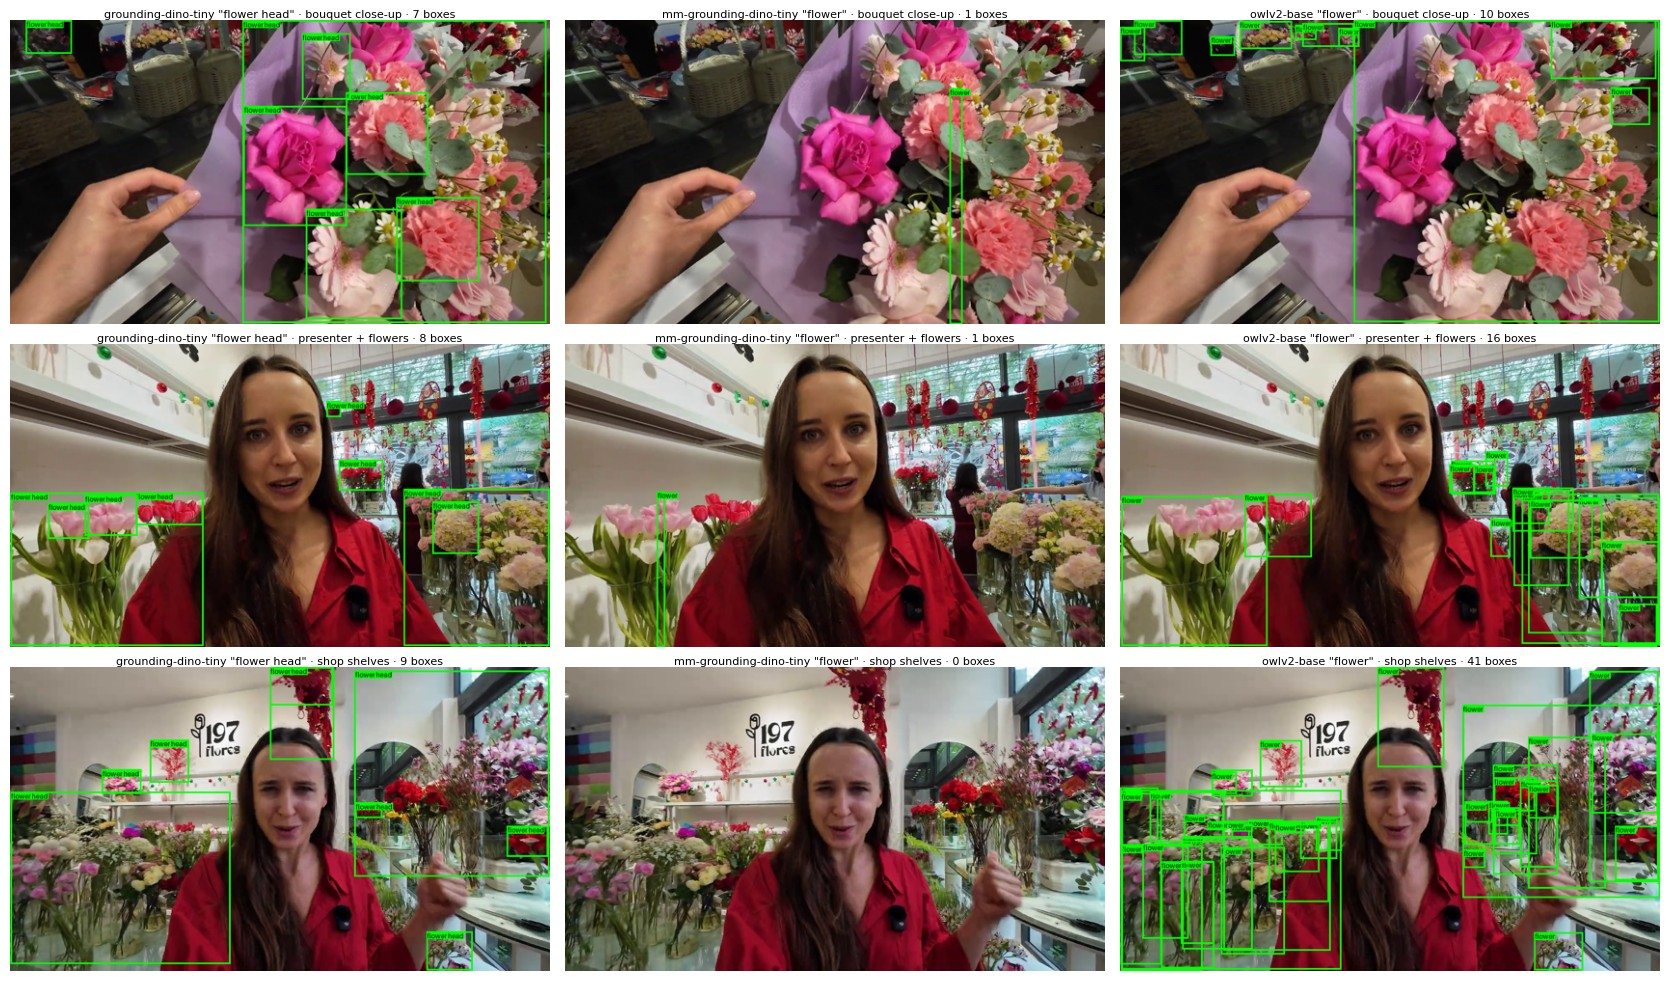

In [8]:
def show_grid(frame_names, model_names, threshold=THRESHOLD, width=560):
    fig, axes = plt.subplots(len(frame_names), len(model_names),
                             figsize=(5.6 * len(model_names), 3.3 * len(frame_names)),
                             squeeze=False)
    for r, frame_name in enumerate(frame_names):
        image = eval_frames[frame_name].image
        for c, model_name in enumerate(model_names):
            prompt_name = best_prompt[model_name]
            dets = kept(model_name, prompt_name, frame_name, threshold)
            drawn = draw_detections(image, dets, width=4, show_score=False)
            axes[r][c].imshow(drawn.resize((width, int(width * image.height / image.width))))
            axes[r][c].set_title(f'{model_name} "{prompt_name}" · {frame_name} · {len(dets)} boxes', fontsize=8, pad=2)
            axes[r][c].axis("off")
    plt.tight_layout()
    plt.show()


show_grid(["bouquet close-up", "presenter + flowers", "shop shelves"], list(MODELS))

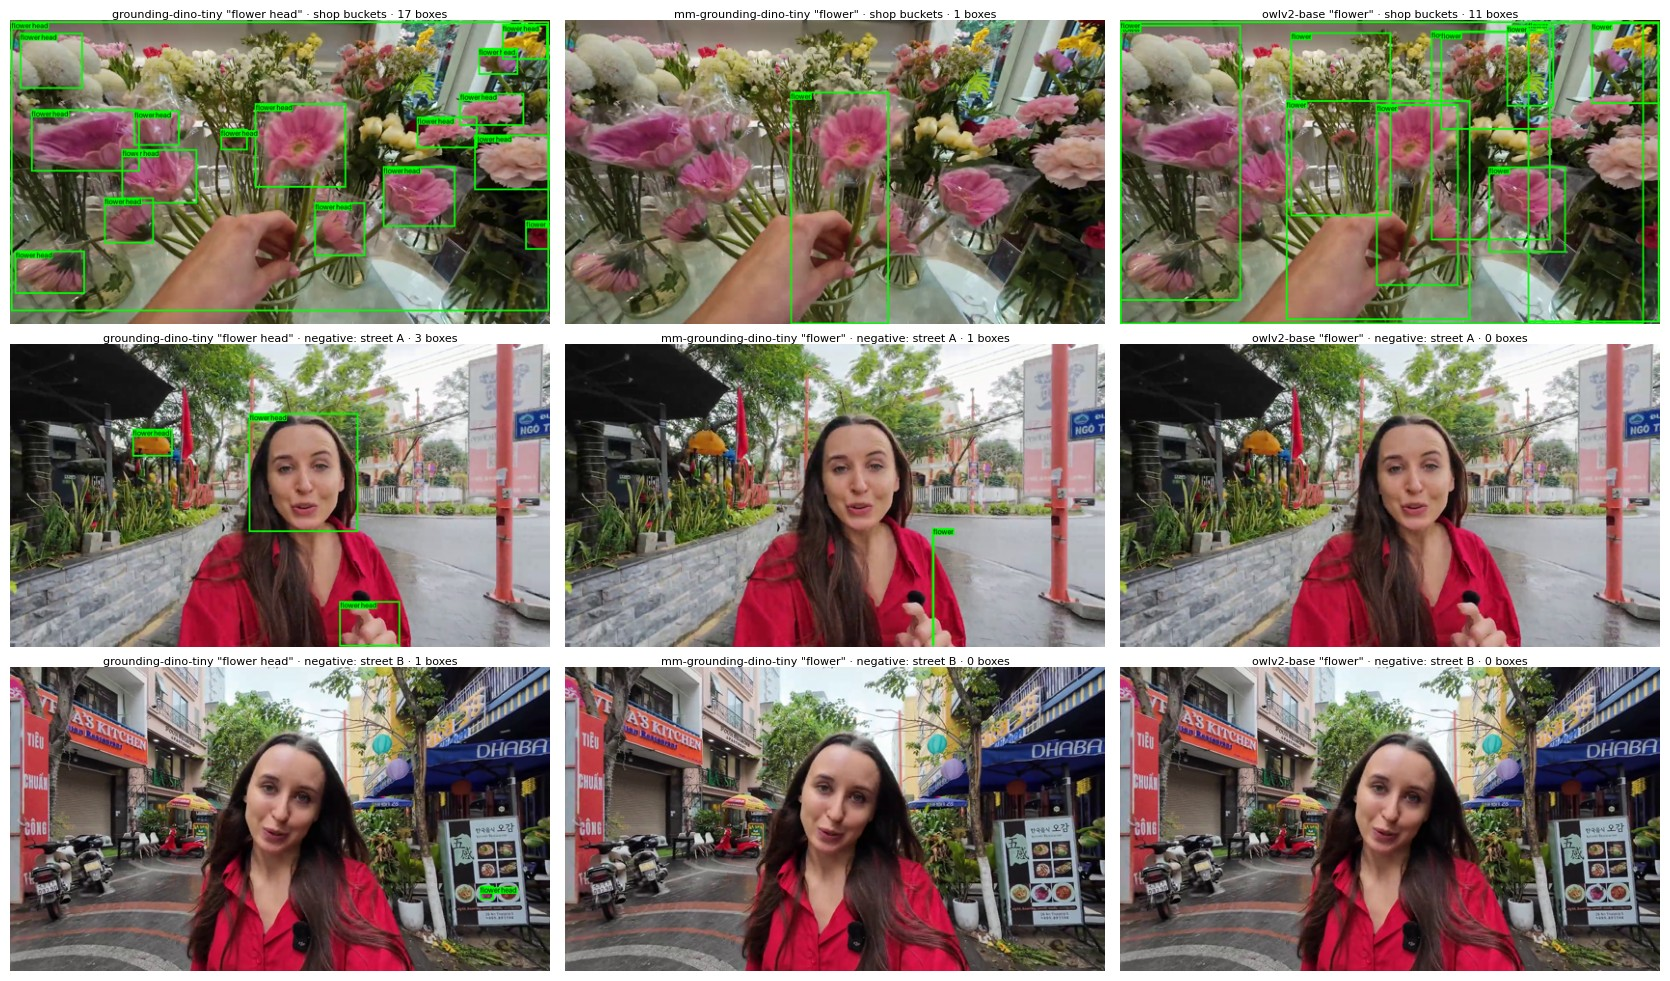

In [9]:
show_grid(["shop buckets", "negative: street A", "negative: street B"], list(MODELS))

## 5 · Prompts matter

Open-vocabulary detectors read the text literally. "flower", "flowers",
"flower head" and "bouquet" can give very different boxes, and listing
species ("rose", "lily", ...) asks the model to do part of the
classification job as well. We try several prompts with the fastest model.

In [10]:
EXPLORE = "grounding-dino-tiny"
PROMPT_SETS = {
    "flower": ["flower"],
    "flowers": ["flowers"],
    "flower head": ["flower head"],
    "bouquet": ["bouquet"],
    "species list": ["rose", "carnation", "gerbera", "lily", "tulip", "chrysanthemum"],
}
PROMPT_FRAMES = ["bouquet close-up", "presenter + flowers"]

detector = OpenVocabDetector(MODELS[EXPLORE])
prompt_dets = {}
for label, prompts in PROMPT_SETS.items():
    for frame_name in PROMPT_FRAMES:
        prompt_dets[(label, frame_name)] = detector.detect(
            eval_frames[frame_name].image, prompts, threshold=0.15)
del detector
gc.collect()

rows = []
for (label, frame_name), dets in prompt_dets.items():
    good = [d for d in dets if d.score >= 0.25]
    rows.append({"prompt": label, "frame": frame_name, "boxes >= 0.25": len(good),
                 "best score": round(max((d.score for d in dets), default=0), 2),
                 "median box area (% frame)": round(100 * float(np.median([d.area for d in good])) / frame_area, 1) if good else 0})
pd.DataFrame(rows).pivot(index="prompt", columns="frame")

Loading weights:   0%|          | 0/978 [00:00<?, ?it/s]

Loading weights:  58%|█████▊    | 568/978 [00:00<00:00, 5632.71it/s]

Loading weights: 100%|██████████| 978/978 [00:00<00:00, 8187.54it/s]

boxes >= 0.25                           best score                     median box area (% frame)                    
frame        bouquet close-up presenter + flowers bouquet close-up presenter + flowers          bouquet close-up presenter + flowers
prompt                                                                                                                              
bouquet                     3                   5             0.76                0.52                       7.6                 6.8
flower                      3                   5             0.62                0.40                       7.6                 6.9
flower head                 7                   8             0.71                0.45                       4.3                 1.3
flowers                     7                   5             0.70                0.52                       4.3                 1.3
species list                2                   4             0.55                0.38                      31.4                13.1

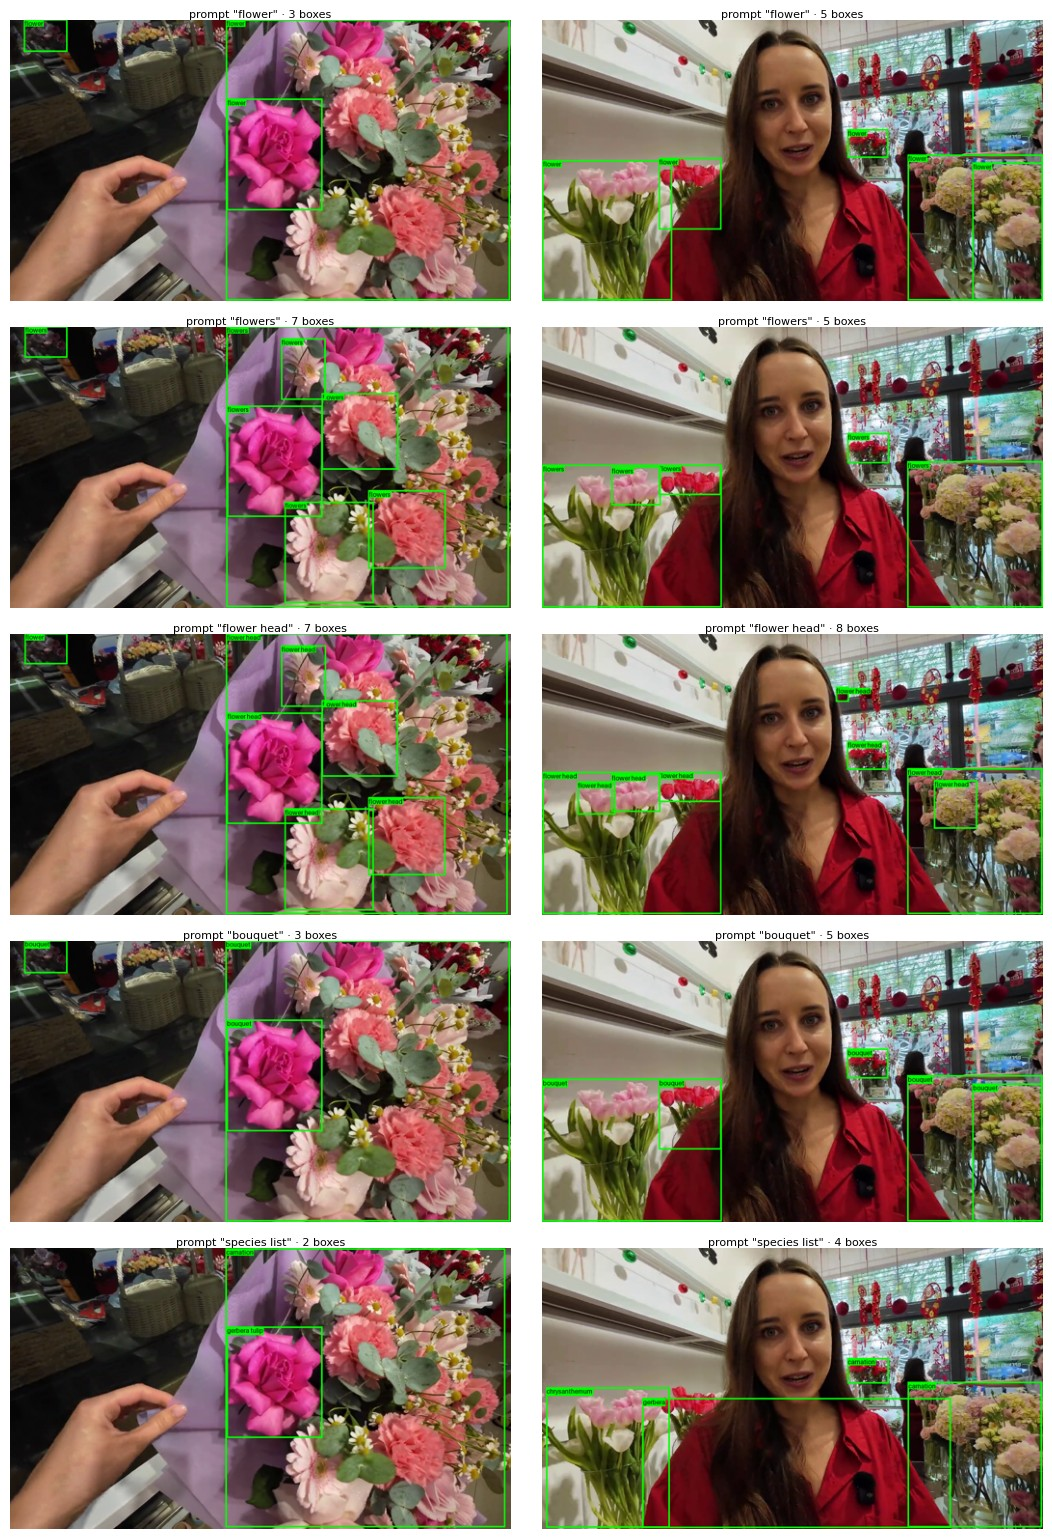

In [11]:
fig, axes = plt.subplots(len(PROMPT_SETS), 2, figsize=(11, 3.1 * len(PROMPT_SETS)))
for r, label in enumerate(PROMPT_SETS):
    for c, frame_name in enumerate(PROMPT_FRAMES):
        image = eval_frames[frame_name].image
        good = [d for d in prompt_dets[(label, frame_name)] if d.score >= 0.25]
        drawn = draw_detections(image, good, width=4, show_score=False)
        axes[r][c].imshow(drawn.resize((520, 292)))
        axes[r][c].set_title(f'prompt "{label}" · {len(good)} boxes', fontsize=8, pad=2)
        axes[r][c].axis("off")
plt.tight_layout()
plt.show()

## 6 · Thresholds and box sizes

No ground truth here (nobody has drawn the "right" boxes), so we look at how
behaviour changes with the threshold, and at box **size**. A bouquet can be
boxed as one object or as its many flowers; for our use we want the flowers.

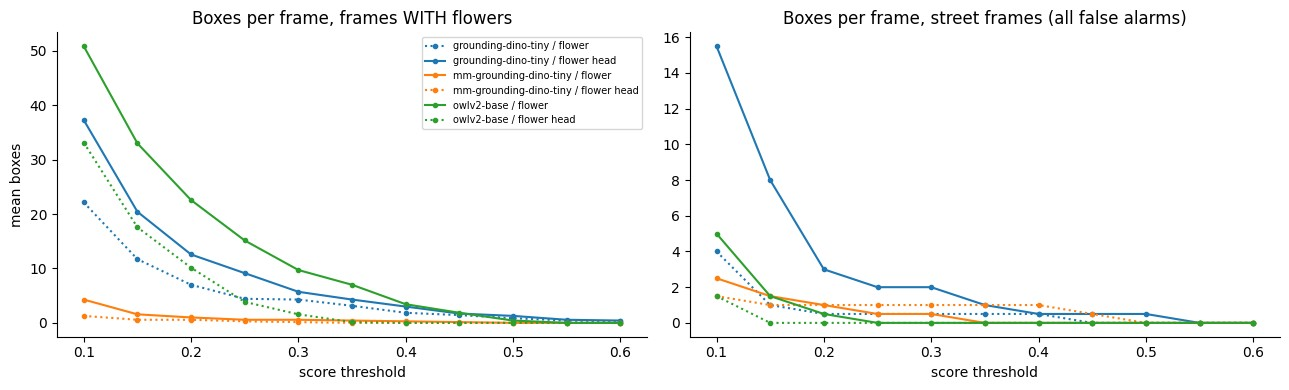

In [12]:
thresholds = np.round(np.arange(0.10, 0.61, 0.05), 2)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
colors = dict(zip(MODELS, ["tab:blue", "tab:orange", "tab:green"]))
flower_frames = [f for f in EVAL_TIMES if not f.startswith("negative")]
street_frames = [f for f in EVAL_TIMES if f.startswith("negative")]
for model_name in MODELS:
    for prompt_name in BENCH_PROMPTS:
        style = "-" if prompt_name == best_prompt[model_name] else ":"
        for ax, frames in ((axes[0], flower_frames), (axes[1], street_frames)):
            counts = [np.mean([len(kept(model_name, prompt_name, f, t)) for f in frames])
                      for t in thresholds]
            ax.plot(thresholds, counts, style, color=colors[model_name], marker="o", ms=3,
                    label=f"{model_name} / {prompt_name}")
axes[0].set(title="Boxes per frame, frames WITH flowers", xlabel="score threshold", ylabel="mean boxes")
axes[1].set(title="Boxes per frame, street frames (all false alarms)", xlabel="score threshold")
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

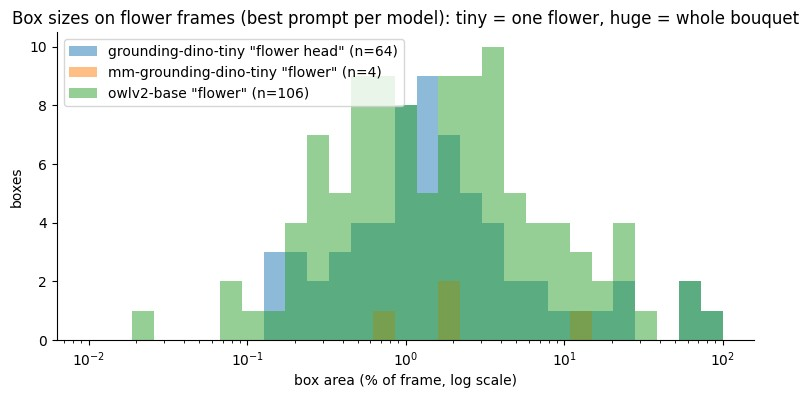

In [13]:
fig, ax = plt.subplots(figsize=(9, 4))
for model_name in MODELS:
    areas = [100 * d.area / frame_area for f in EVAL_TIMES if not f.startswith("negative")
             for d in kept(model_name, best_prompt[model_name], f)]
    ax.hist(areas, bins=np.logspace(-2, 2, 30), alpha=0.5,
            label=f'{model_name} "{best_prompt[model_name]}" (n={len(areas)})')
ax.set_xscale("log")
ax.set(xlabel="box area (% of frame, log scale)", ylabel="boxes",
       title="Box sizes on flower frames (best prompt per model): tiny = one flower, huge = whole bouquet")
ax.legend()
plt.show()

## 7 · Run it on a clip

The two viable detectors over a stretch of the video at one frame per second
with each model's best prompt: 15 s inside the shop, then 5 s of street. Each
writes an annotated mp4 you can play back (`*_<model>_annotated.mp4` next to
the video, git-ignored), and we plot how many boxes appear over time.

Change `RUN_MODELS` / `SEGMENTS` to try other detectors or moments.

In [14]:
RUN_MODELS = ["grounding-dino-tiny", "owlv2-base"]
RUN_THRESHOLD = 0.25
SEGMENTS = [("shop", 90, 105), ("street", 300, 305)]

timeline, annotated = [], {}
for model_name in RUN_MODELS:
    detector = OpenVocabDetector(MODELS[model_name])
    annotated[model_name] = []
    t0 = time.perf_counter()
    for segment, start, end in SEGMENTS:
        for frame in video.sample_frames(path, every_s=1.0, start_s=start, end_s=end):
            dets = detector.detect(frame.image, [best_prompt[model_name]], threshold=RUN_THRESHOLD)
            timeline.append({"model": model_name, "segment": segment,
                             "time_s": frame.time_s, "boxes": len(dets)})
            annotated[model_name].append(
                draw_detections(frame.image, dets, width=4, show_score=False))
    del detector
    gc.collect()
    n = len(annotated[model_name])
    elapsed = time.perf_counter() - t0
    out_path = video.write_video(
        annotated[model_name],
        path.with_name(f"{path.stem}_{model_name}_annotated.mp4"), fps=2)
    print(f"{model_name}: {n} frames in {elapsed:.0f} s ({elapsed / n:.1f} s/frame) -> {out_path.name}")
timeline = pd.DataFrame(timeline)

Loading weights:   0%|          | 0/978 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 978/978 [00:00<00:00, 30979.75it/s]

grounding-dino-tiny: 20 frames in 279 s (14.0 s/frame) -> QSVyyrKea14_grounding-dino-tiny_annotated.mp4


Loading weights:   0%|          | 0/418 [00:00<?, ?it/s]

Loading weights:  27%|██▋       | 111/418 [00:00<00:00, 968.77it/s]

Loading weights:  50%|████▉     | 208/418 [00:00<00:00, 545.02it/s]

Loading weights: 100%|██████████| 418/418 [00:00<00:00, 925.22it/s]

owlv2-base: 20 frames in 185 s (9.2 s/frame) -> QSVyyrKea14_owlv2-base_annotated.mp4


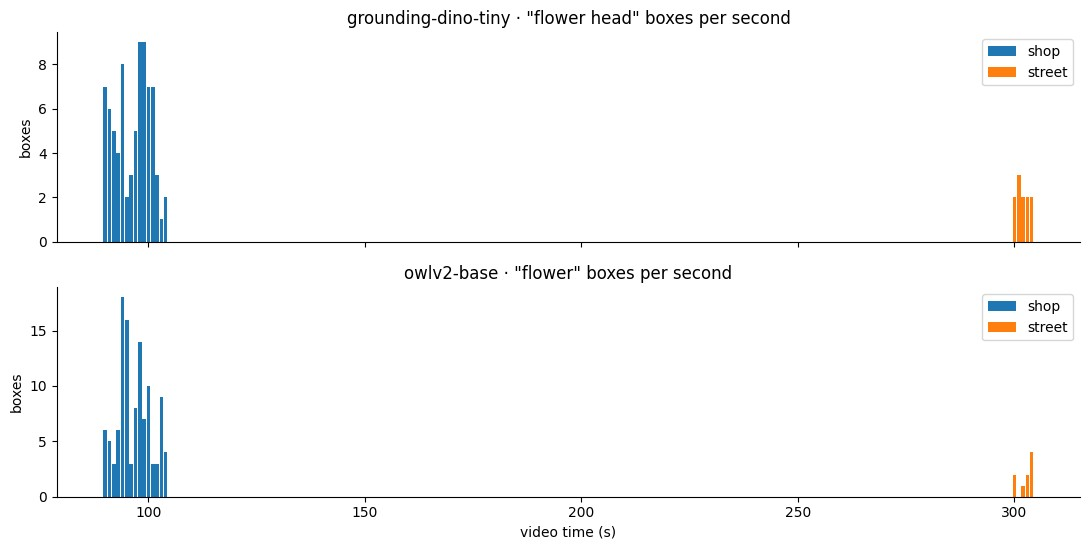

In [15]:
fig, axes = plt.subplots(len(RUN_MODELS), 1, figsize=(11, 2.8 * len(RUN_MODELS)), sharex=True)
for ax, model_name in zip(np.atleast_1d(axes), RUN_MODELS):
    part = timeline[timeline["model"] == model_name]
    for segment, rows in part.groupby("segment"):
        ax.bar(rows["time_s"], rows["boxes"], width=0.8, label=segment)
    ax.set(ylabel="boxes", title=f'{model_name} · "{best_prompt[model_name]}" boxes per second')
    ax.legend()
axes[-1].set_xlabel("video time (s)")
plt.tight_layout()
plt.show()

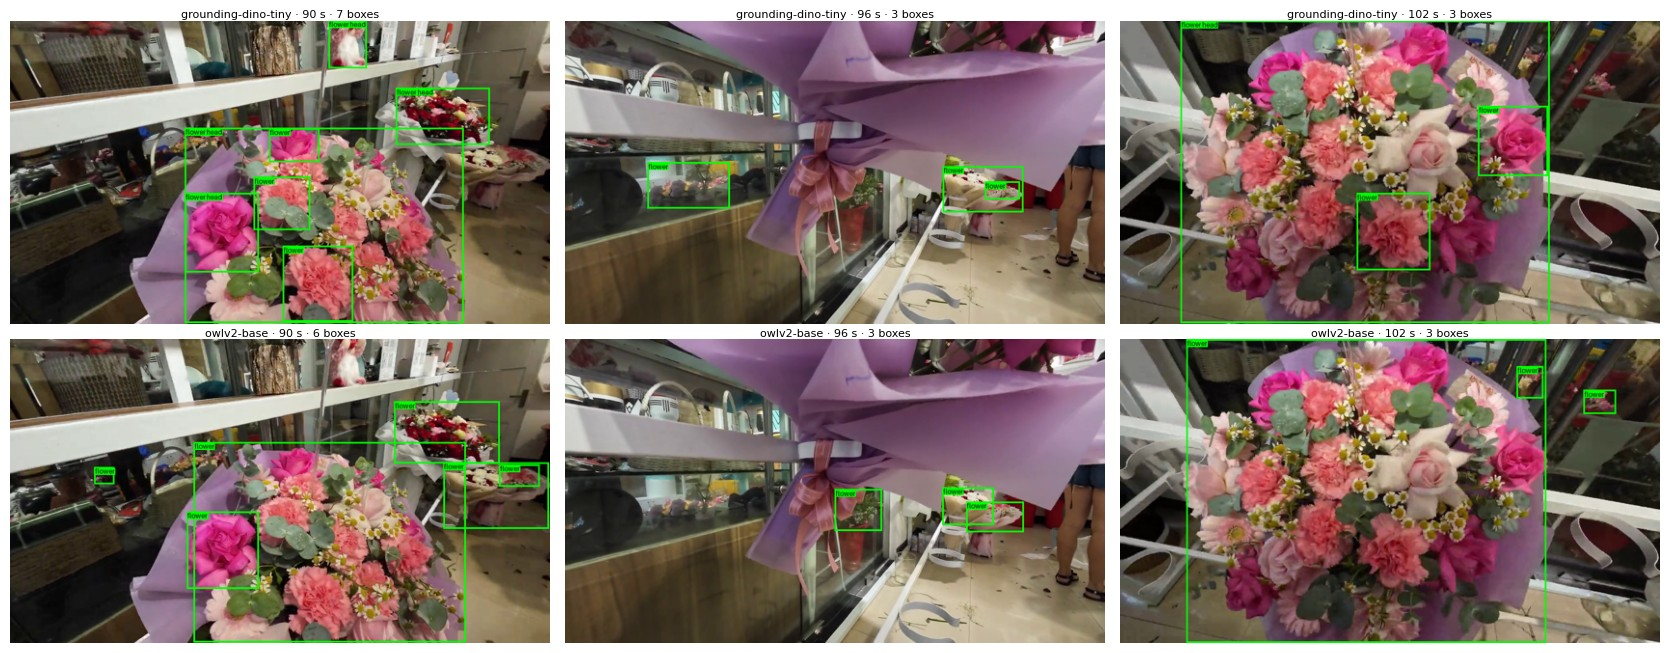

In [16]:
# The same three shop moments, one row per model.
shop = timeline[(timeline["segment"] == "shop")]["time_s"].unique()
picks = [0, 6, 12]
fig, axes = plt.subplots(len(RUN_MODELS), len(picks), figsize=(5.6 * len(picks), 3.3 * len(RUN_MODELS)),
                         squeeze=False)
for r, model_name in enumerate(RUN_MODELS):
    for c, i in enumerate(picks):
        axes[r][c].imshow(annotated[model_name][i].resize((560, 315)))
        boxes = timeline[(timeline["model"] == model_name) & (timeline["time_s"] == shop[i])]["boxes"].iloc[0]
        axes[r][c].set_title(f"{model_name} · {shop[i]:.0f} s · {boxes} boxes", fontsize=8, pad=2)
        axes[r][c].axis("off")
plt.tight_layout()
plt.show()

## 8 · One second at full frame rate

So far we looked at one frame per second. Here we zoom in on **a single
second, all 30 frames**, to see how the detectors behave from frame to frame:
do the boxes stay on the same flowers, do they flicker, and what does one
second of video cost in compute?

**Choosing the second.** We want a bouquet clearly visible in every frame,
not blurred, with nothing in front of it, and a little camera motion (a frozen
second would flatter the models). From about 100 s to 109 s the pink bouquet
fills the view. **107.0-108.0 s** is the chosen window (red borders below): the
camera drifts steadily toward the bouquet, no hands or people get in the way,
and the light is even. The next second (108-109 s) is almost static, which
would be too easy.

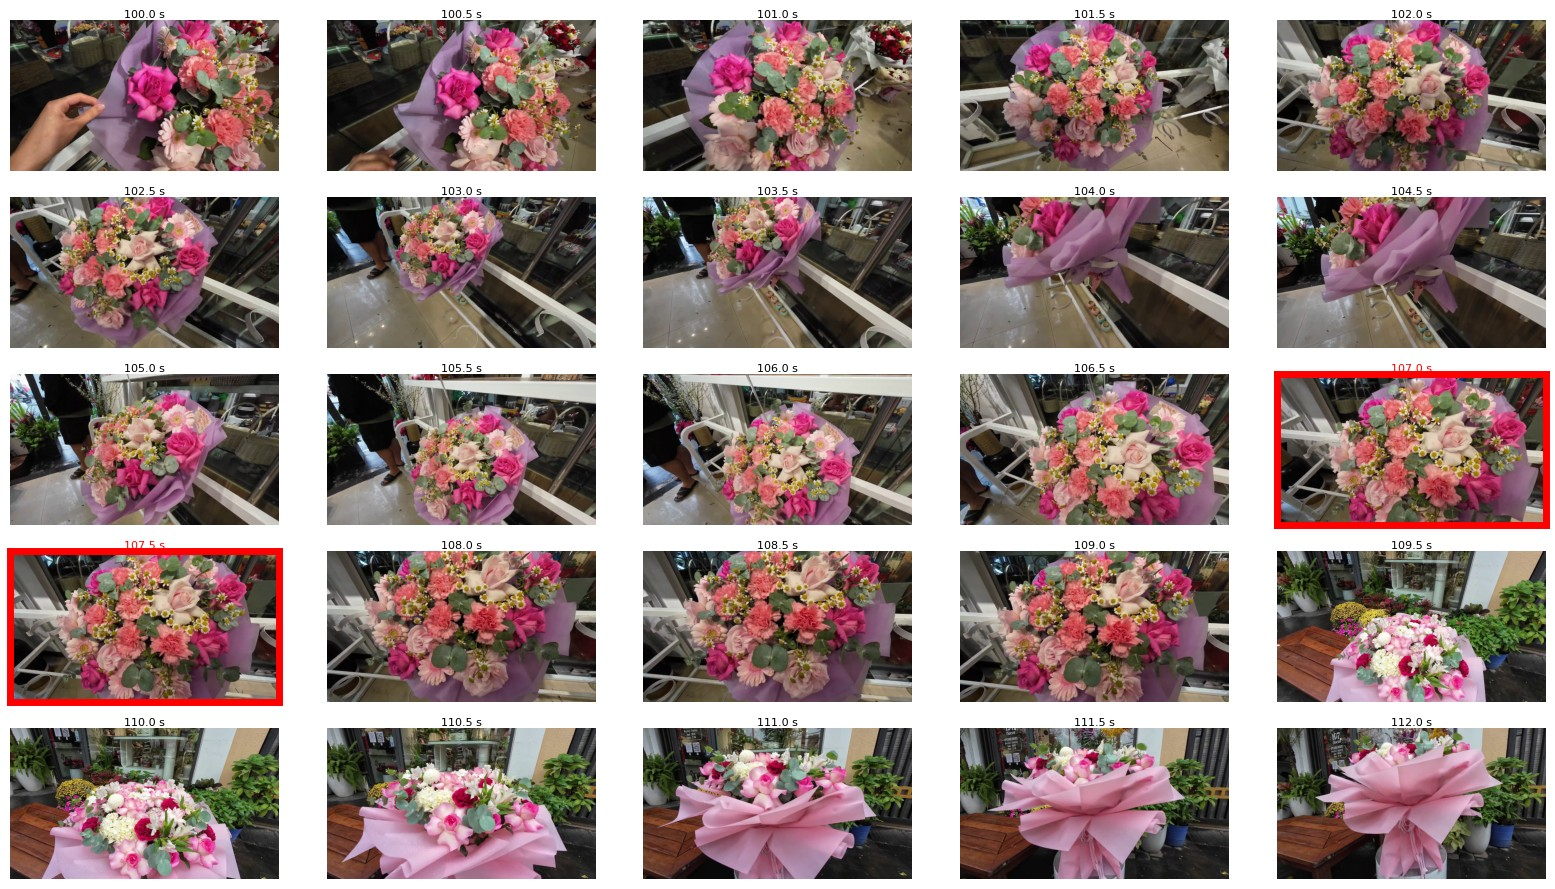

In [3]:
WINDOW_START, WINDOW_S = 107.0, 1.0
WINDOW_MODELS = ["grounding-dino-tiny", "owlv2-base"]      # the two viable detectors
WINDOW_PROMPTS = {"grounding-dino-tiny": "flower head",    # each one's best prompt,
                  "owlv2-base": "flower"}                  # found in section 3
WINDOW_LOW, WINDOW_THRESHOLD = 0.10, 0.25

candidates = [t / 2 for t in range(200, 225)]              # 100 s .. 112 s, every 0.5 s
fig, axes = plt.subplots(5, 5, figsize=(16, 9))
for ax, t in zip(axes.ravel(), candidates):
    chosen = WINDOW_START <= t < WINDOW_START + WINDOW_S
    ax.imshow(video.read_frame(path, t).image)
    ax.set_xticks([]); ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(chosen); spine.set_color("red"); spine.set_linewidth(5)
    ax.set_title(f"{t:.1f} s", fontsize=8, pad=2, color="red" if chosen else "black")
plt.tight_layout()
plt.show()

The chosen second as raw video: every 3rd frame (0.1 s apart), no boxes yet.

30 frames, 107.000 s to 107.967 s


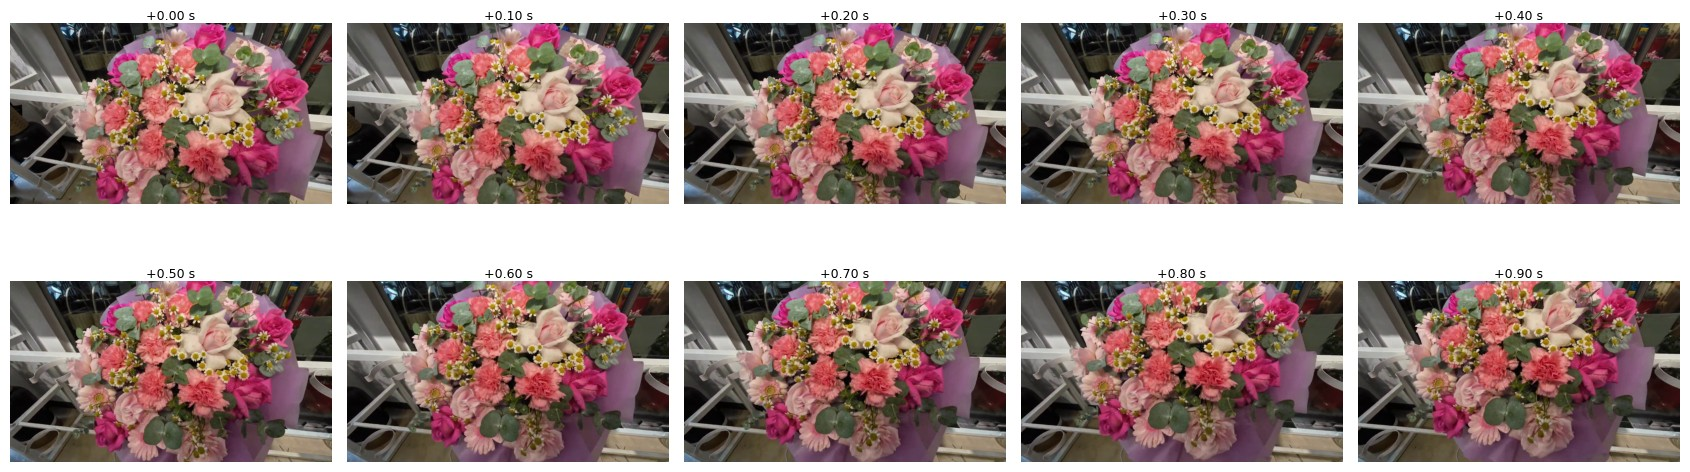

In [4]:
frames = list(video.sample_frames(path, every_s=1 / info.fps,
                                  start_s=WINDOW_START, end_s=WINDOW_START + WINDOW_S))
print(f"{len(frames)} frames, {frames[0].time_s:.3f} s to {frames[-1].time_s:.3f} s")

fig, axes = plt.subplots(2, 5, figsize=(17, 6))
for ax, k in zip(axes.ravel(), range(0, len(frames), 3)):
    ax.imshow(frames[k].image.resize((640, 360)))
    ax.set_title(f"+{frames[k].time_s - frames[0].time_s:.2f} s", fontsize=9, pad=2)
    ax.axis("off")
plt.tight_layout()
plt.show()

Now both detectors on **every one of the 30 frames**, each with its best
prompt. This is the expensive part: the seconds of compute it takes to process
one second of video are printed at the end of each model's run.

In [5]:
window_dets, window_seconds = {}, {}
for model_name in WINDOW_MODELS:
    detector = OpenVocabDetector(MODELS[model_name])
    prompt = [WINDOW_PROMPTS[model_name]]
    t0 = time.perf_counter()
    window_dets[model_name] = [
        detector.detect(frame.image, prompt, threshold=WINDOW_LOW) for frame in frames]
    window_seconds[model_name] = time.perf_counter() - t0
    del detector
    gc.collect()
    print(f'{model_name} "{prompt[0]}": {len(frames)} frames in {window_seconds[model_name]:.0f} s '
          f"= {window_seconds[model_name] / len(frames):.1f} s/frame, i.e. "
          f"{window_seconds[model_name] / WINDOW_S:.0f} s of compute per second of video")

C:\Users\carl0\vsc\cat-project\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/978 [00:00<?, ?it/s]

Loading weights:   3%|▎         | 34/978 [00:00<00:03, 310.64it/s]

Loading weights:  10%|▉         | 94/978 [00:00<00:01, 472.21it/s]

Loading weights:  15%|█▍        | 142/978 [00:00<00:03, 222.37it/s]

...

Loading weights:  23%|██▎       | 98/418 [00:00<00:02, 153.74it/s]

Loading weights:  28%|██▊       | 115/418 [00:00<00:02, 118.76it/s]

Loading weights:  31%|███       | 129/418 [00:00<00:02, 116.95it/s]

Loading weights: 100%|██████████| 418/418 [00:00<00:00, 437.86it/s]

owlv2-base "flower": 30 frames in 872 s = 29.1 s/frame, i.e. 872 s of compute per second of video


### The boxes on the frames

Every 3rd frame with the boxes overlaid (score >= 0.25), one figure per model.

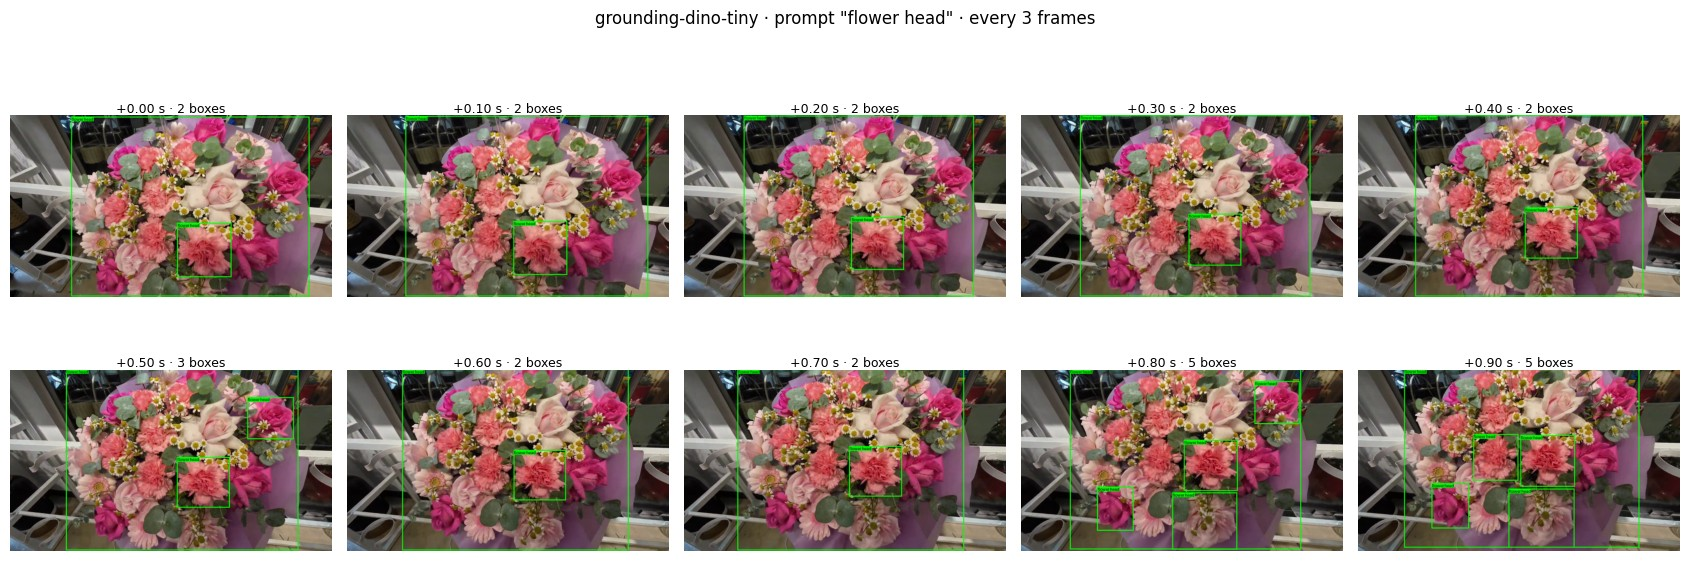

In [6]:
def show_strip(model_name, every=3, threshold=WINDOW_THRESHOLD):
    fig, axes = plt.subplots(2, 5, figsize=(17, 6.4))
    for ax, k in zip(axes.ravel(), range(0, len(frames), every)):
        boxes = [d for d in window_dets[model_name][k] if d.score >= threshold]
        drawn = draw_detections(frames[k].image, boxes, width=4, show_score=False)
        ax.imshow(drawn.resize((640, 360)))
        ax.set_title(f"+{frames[k].time_s - frames[0].time_s:.2f} s · {len(boxes)} boxes",
                     fontsize=9, pad=2)
        ax.axis("off")
    fig.suptitle(f'{model_name} · prompt "{WINDOW_PROMPTS[model_name]}" · every {every} frames',
                 fontsize=12)
    plt.tight_layout()
    plt.show()


show_strip("grounding-dino-tiny")

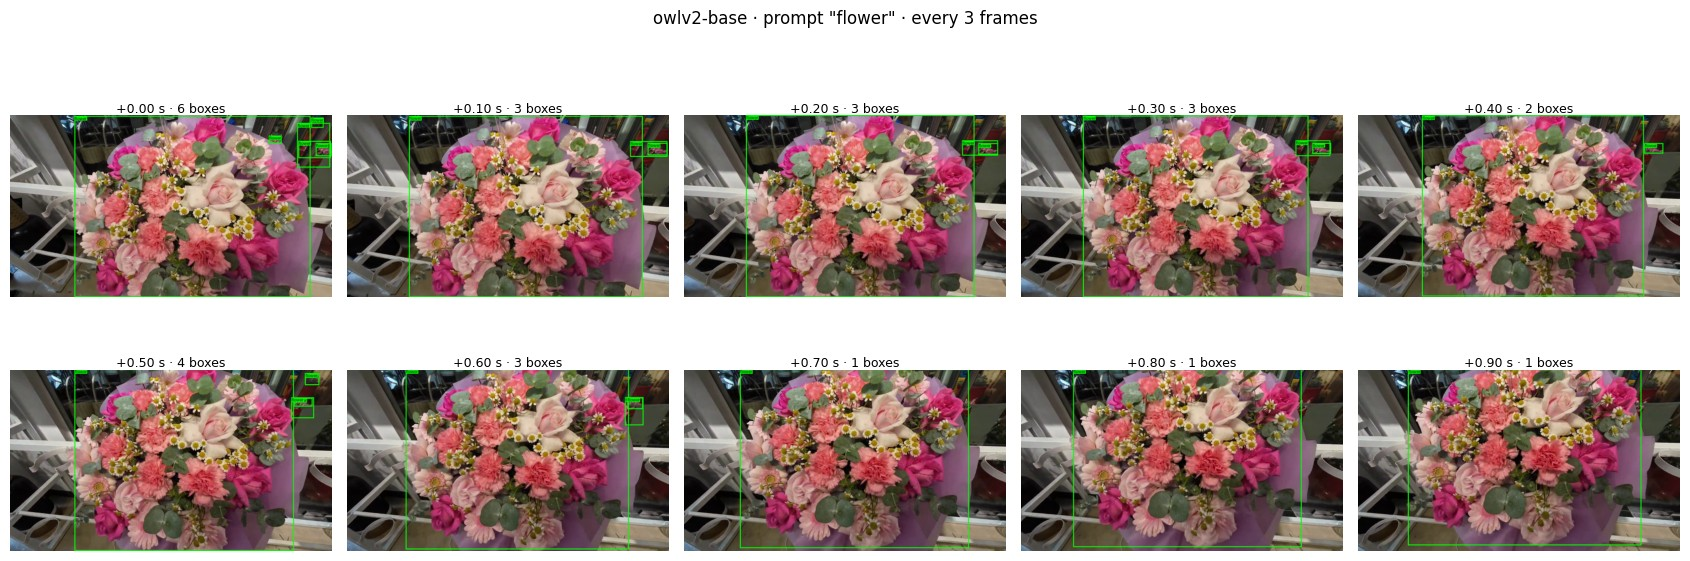

In [7]:
show_strip("owlv2-base")

### All 30 frames' boxes on one image

Every box from every frame drawn on the middle frame, **coloured by time**
(purple = start of the second, yellow = end). If a detector locks onto the
same flowers, the outlines pile up into tight, single-coloured-band stacks. If
it flickers or drifts, you see a smear. Part of the drift is real: the camera
is moving.

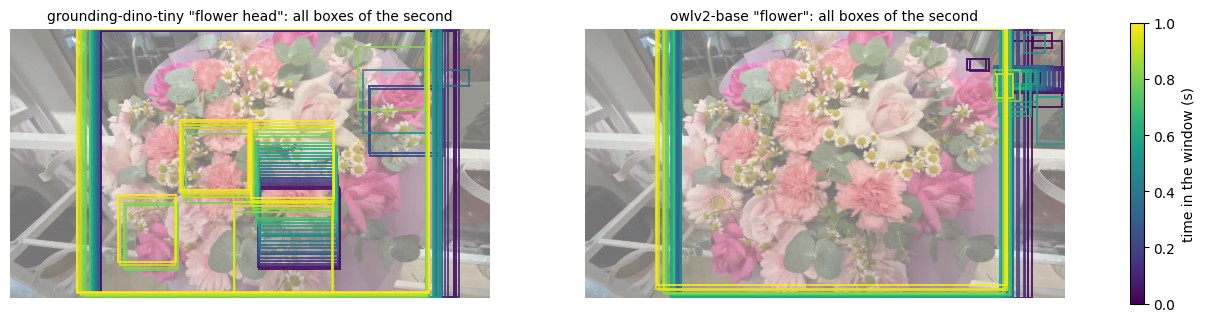

In [8]:
from matplotlib.patches import Rectangle

cmap = plt.get_cmap("viridis")
mid = frames[len(frames) // 2].image
fig, axes = plt.subplots(1, len(WINDOW_MODELS), figsize=(8.5 * len(WINDOW_MODELS), 5.2))
for ax, model_name in zip(np.atleast_1d(axes), WINDOW_MODELS):
    ax.imshow(mid, alpha=0.55)
    for k, dets in enumerate(window_dets[model_name]):
        for d in dets:
            if d.score >= WINDOW_THRESHOLD:
                ax.add_patch(Rectangle((d.box[0], d.box[1]), d.width, d.height, fill=False,
                                       ec=cmap(k / (len(frames) - 1)), lw=1.4, alpha=0.85))
    ax.set_title(f'{model_name} "{WINDOW_PROMPTS[model_name]}": all boxes of the second', fontsize=10)
    ax.axis("off")
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(0, WINDOW_S))
fig.colorbar(sm, ax=axes, shrink=0.7, label="time in the window (s)")
plt.show()

### Do the boxes stay on the same flowers?

Two numbers per frame. **Boxes per frame**: does the count hold steady?
**Persistence**: of the boxes in the previous frame, what share can be found
again in this frame (same place, IoU >= 0.5)? A steady detector sits near 1.
Anything lower means boxes appear and disappear, which is what a tracker would
have to smooth over.

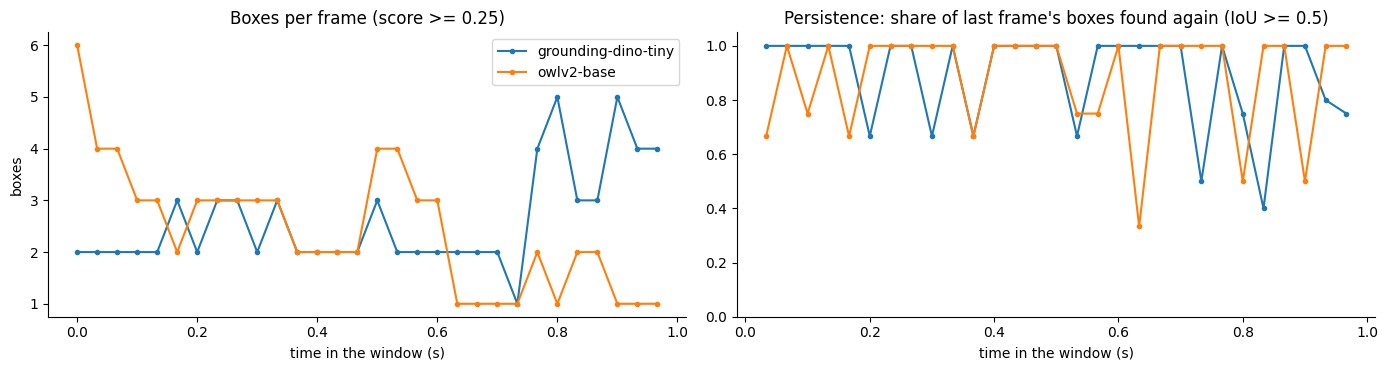

,s compute per s video,mean boxes / frame,min-max boxes,frames with 0 boxes,mean persistence
grounding-dino-tiny,607,2.6,1-5,0,0.89
owlv2-base,872,2.4,1-6,0,0.88


In [9]:
from bouquet_checker.detection import match_boxes

t_axis = [f.time_s - frames[0].time_s for f in frames]
stats = {}
for model_name in WINDOW_MODELS:
    per_frame = [[d.box for d in dets if d.score >= WINDOW_THRESHOLD]
                 for dets in window_dets[model_name]]
    persistence = [np.nan] + [
        len(match_boxes(prev, cur, 0.5)) / len(prev) if prev else np.nan
        for prev, cur in zip(per_frame, per_frame[1:])]
    stats[model_name] = {"counts": np.array([len(b) for b in per_frame]),
                         "persistence": np.array(persistence)}

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
for model_name in WINDOW_MODELS:
    axes[0].plot(t_axis, stats[model_name]["counts"], marker="o", ms=3, label=model_name)
    axes[1].plot(t_axis, stats[model_name]["persistence"], marker="o", ms=3, label=model_name)
axes[0].set(title=f"Boxes per frame (score >= {WINDOW_THRESHOLD})",
            xlabel="time in the window (s)", ylabel="boxes")
axes[1].set(title="Persistence: share of last frame's boxes found again (IoU >= 0.5)",
            xlabel="time in the window (s)", ylim=(0, 1.05))
axes[0].legend()
plt.tight_layout()
plt.show()

pd.DataFrame({
    "s compute per s video": {m: round(window_seconds[m] / WINDOW_S) for m in WINDOW_MODELS},
    "mean boxes / frame": {m: round(float(stats[m]["counts"].mean()), 1) for m in WINDOW_MODELS},
    "min-max boxes": {m: f"{stats[m]['counts'].min()}-{stats[m]['counts'].max()}" for m in WINDOW_MODELS},
    "frames with 0 boxes": {m: int((stats[m]["counts"] == 0).sum()) for m in WINDOW_MODELS},
    "mean persistence": {m: round(float(np.nanmean(stats[m]["persistence"])), 2) for m in WINDOW_MODELS},
})

### Watch it move

The whole second, both detectors side by side, slowed to 10 frames per second
(so it lasts 3 s). The animated GIF and an mp4 are also saved next to the
video (git-ignored).

In [10]:
from IPython.display import Image as IPyImage
from IPython.display import display
from PIL import Image


def side_by_side(k, tile=(480, 270)):
    tiles = []
    for model_name in WINDOW_MODELS:
        boxes = [d for d in window_dets[model_name][k] if d.score >= WINDOW_THRESHOLD]
        drawn = draw_detections(frames[k].image, boxes, width=4, show_score=False)
        tiles.append(drawn.resize(tile))
    canvas = Image.new("RGB", (tile[0] * len(tiles), tile[1]))
    for i, one in enumerate(tiles):
        canvas.paste(one, (tile[0] * i, 0))
    return canvas


slowmo = [side_by_side(k) for k in range(len(frames))]
gif_path = path.with_name(f"{path.stem}_1s_side_by_side.gif")
slowmo[0].save(gif_path, save_all=True, append_images=slowmo[1:], duration=100, loop=0, optimize=True)
mp4_path = video.write_video(slowmo, path.with_name(f"{path.stem}_1s_side_by_side.mp4"), fps=10)
print(f"left: {WINDOW_MODELS[0]}, right: {WINDOW_MODELS[1]}")
print(f"{gif_path.name}: {gif_path.stat().st_size / 1e6:.1f} MB, {mp4_path.name}: {mp4_path.stat().st_size / 1e6:.1f} MB")
if gif_path.stat().st_size < 2_500_000:
    display(IPyImage(filename=str(gif_path)))

left: grounding-dino-tiny, right: owlv2-base
QSVyyrKea14_1s_side_by_side.gif: 4.8 MB, QSVyyrKea14_1s_side_by_side.mp4: 1.0 MB


## 9 · Take-aways

* **Yes: an open-vocabulary detector finds flowers with no flower training,
  but far from all of them.** In the shop frames both viable models boxed
  roses, carnations, gerberas and bunches of tulips. In the clearest second
  we could find (section 8: the bouquet fills the view, roughly 20-30 flower
  heads), Grounding DINO boxed 1-5 per frame (mean 2.6) and OWLv2 1-6 (mean
  2.4), mostly one box around the *whole bouquet*. Recall on individual
  flowers is low even in the best case.
* **The word you type matters as much as the model, and the best word differs
  per model.** Grounding DINO tiny: "flower head" gives 9.1 boxes per flower
  frame vs 4.4 for "flower". OWLv2 base: "flower" gives 15.1 vs 3.9 for
  "flower head". Species lists ("rose", "lily", ...) give huge boxes with
  wrong names (e.g. "chrysanthemum" on tulips): use the detector to *find*
  flowers, not to *name* them; that is the classifier's job.
* **Trade-off** (score threshold 0.25):
  * *Grounding DINO tiny + "flower head"*: best at isolating individual
    flowers (17 boxes on the bucket frame; in the one-second window it stayed
    locked on one carnation), but the noisiest (2.0 boxes per street frame,
    once including the presenter's face).
  * *OWLv2 base + "flower"*: quiet on the street frames, but it boxes bunches
    and stacks overlapping boxes; in the one-second window it never boxed an
    individual flower, and it fired up to 4 times in the street clip.
  * *MM-Grounding-DINO tiny*: found almost nothing (0.6 boxes per flower
    frame). Not usable for this.
* **Across frames the boxes are fairly steady.** In the one-second window no
  frame was empty, and about 88-89% of the boxes of one frame are found again
  (IoU >= 0.5) in the next. Boxes still appear and vanish as the camera moves,
  which is what a tracker would have to smooth over.
* **Nothing here is real time, and speed on this laptop is unstable.** The
  benchmark measured 9-14 s per frame; the 30-frame run measured 20 s
  (Grounding DINO) and 29 s (OWLv2), with only ~2 GB of RAM free and thermal
  throttling likely. Read it as "10-30 s per frame" (about 0.03-0.1 frames
  per second, i.e. 10-15 minutes of compute per second of video) and do not
  trust the speed ranking of the two models. The strongest models (SAM 3,
  larger Grounding DINO variants) need a datacentre GPU, so these are the best
  *practical* choice here, not the state of the art.
* **Misses are silent.** On the wrapped bouquet seen from the side (about
  96 s) both models find little. An unboxed flower looks "unchecked", and a
  UI must never read as "the bouquet is fine".
* **No ground truth yet:** everything was judged by eye. Hand-label 30-50
  frames to measure recall and precision properly.
* **Path to real time:** use these models offline as *auto-labelers*, fix
  the boxes by hand, then train a small YOLO with one class ("flower"),
  then track each box and classify it.